## Workshop -1 Adding Sunglasses to Your Passport Photo Using OpenC
# NAME: SWETHA K
# REG NO: 212224230284

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


Text(0.5, 1.0, 'Face')

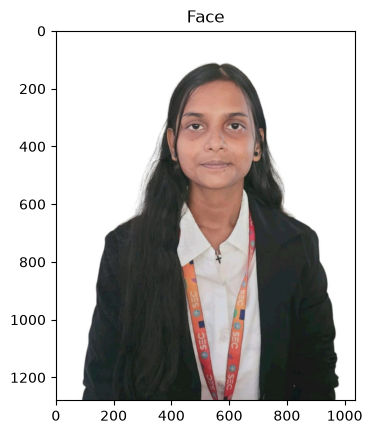

In [3]:
faceImage = cv2.imread(r'C:\Users\admin\Downloads\my photo.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [4]:
faceImage.shape


(1280, 1037, 3)

Text(0.5, 1.0, 'glassPNG')

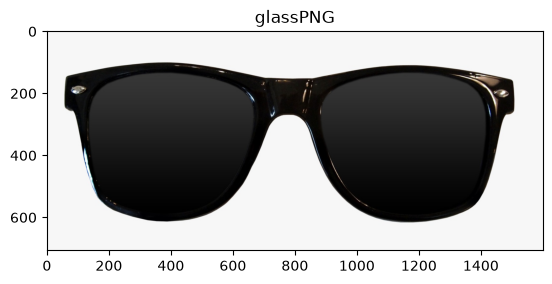

In [5]:
glassPNG = cv2.imread(r'C:\Users\admin\Downloads\Sunglasses.jpeg',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")


In [6]:
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))


image Dimension =(50, 190, 3)


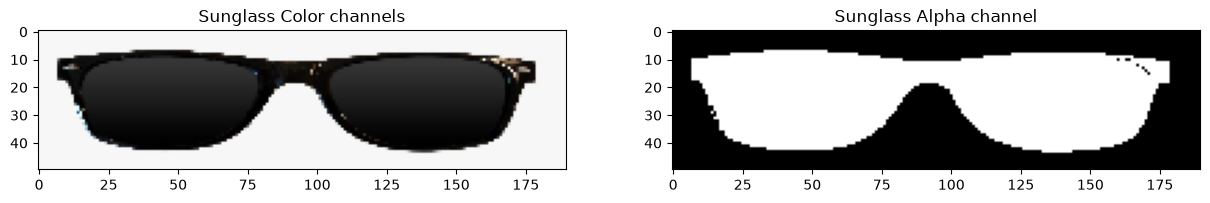

In [7]:
# Separate the color channels
glassBGR = glassPNG[:, :, 0:3]

# Convert BGR to grayscale
gray = cv2.cvtColor(glassPNG, cv2.COLOR_BGR2GRAY)

# Create alpha mask
ret, glassMask1 = cv2.threshold(
    gray, 200, 255, cv2.THRESH_BINARY_INV
)

plt.figure(figsize=[15, 5])

plt.subplot(121)
plt.imshow(glassBGR[:, :, ::-1])
plt.title('Sunglass Color channels')

plt.subplot(122)
plt.imshow(glassMask1, cmap='gray')
plt.title('Sunglass Alpha channel')

plt.show()

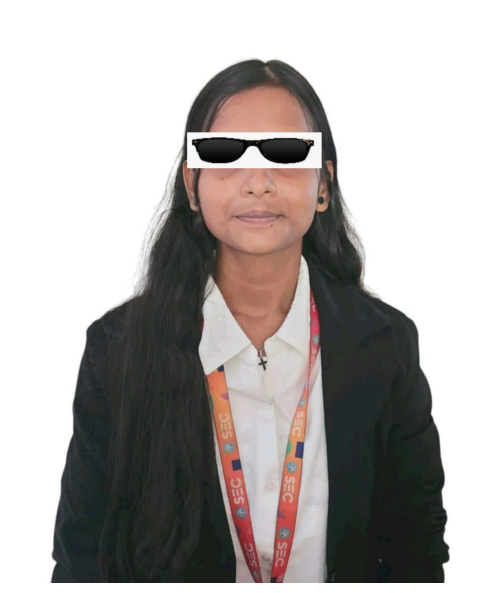

In [8]:
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses
glassBGR_resized = cv2.resize(glassBGR, (300, 80))

# Place sunglasses slightly below
faceWithGlassesNaive[275:355, 395:695] = glassBGR_resized

plt.figure(figsize=(6, 8))
plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.axis('off')
plt.show()

Face image shape: (1280, 1037, 3)
Glasses image shape: (50, 190, 3)
Mask shape: (50, 190)


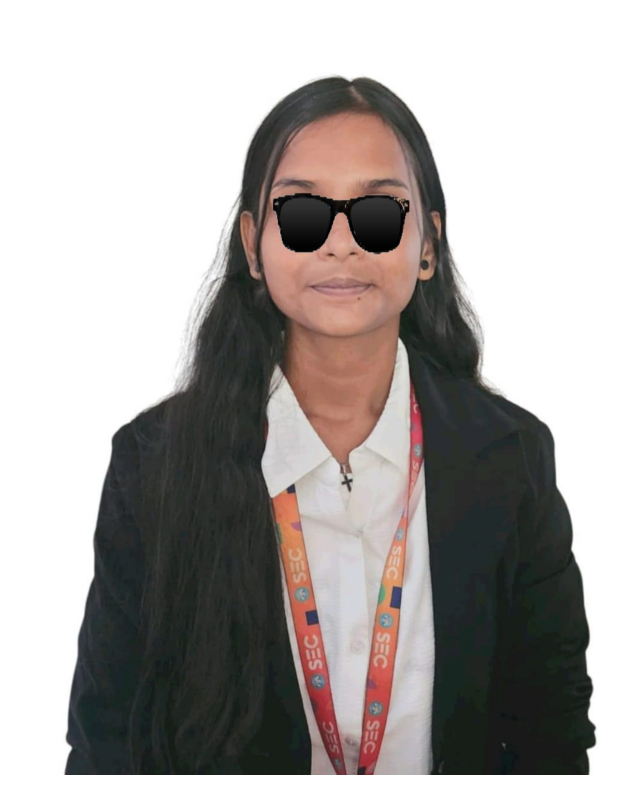

In [9]:
print("Face image shape:", faceImage.shape)
print("Glasses image shape:", glassBGR.shape)
print("Mask shape:", glassMask1.shape)
# Find the actual sunglasses area using the mask
coords = cv2.findNonZero(glassMask1)

x, y, w, h = cv2.boundingRect(coords)

# Crop both glasses and mask
glassBGR = glassBGR[y:y+h, x:x+w]
glassMask1 = glassMask1[y:y+h, x:x+w]
# Create a fresh copy
faceWithGlassesArithmetic = faceImage.copy()

H, W = faceImage.shape[:2]

# Set sunglasses position proportionally
x1 = int(W * 0.425)
x2 = int(W * 0.645)

y1 = int(H * 0.24)
y2 = int(H * 0.32)

eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2]

# Resize glasses and mask
glassBGR = cv2.resize(glassBGR, (eyeROI.shape[1], eyeROI.shape[0]))
glassMask1 = cv2.resize(glassMask1, (eyeROI.shape[1], eyeROI.shape[0]))

# Convert mask into 3 channels
glassMask = cv2.cvtColor(glassMask1, cv2.COLOR_GRAY2BGR)

# Normalize mask
glassMask = glassMask.astype(float) / 255.0

# Arithmetic masking
maskedEye = cv2.multiply(eyeROI.astype(float), 1 - glassMask)
maskedGlass = cv2.multiply(glassBGR.astype(float), glassMask)

# Combine
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace eye region
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal.astype('uint8')

# Display
plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

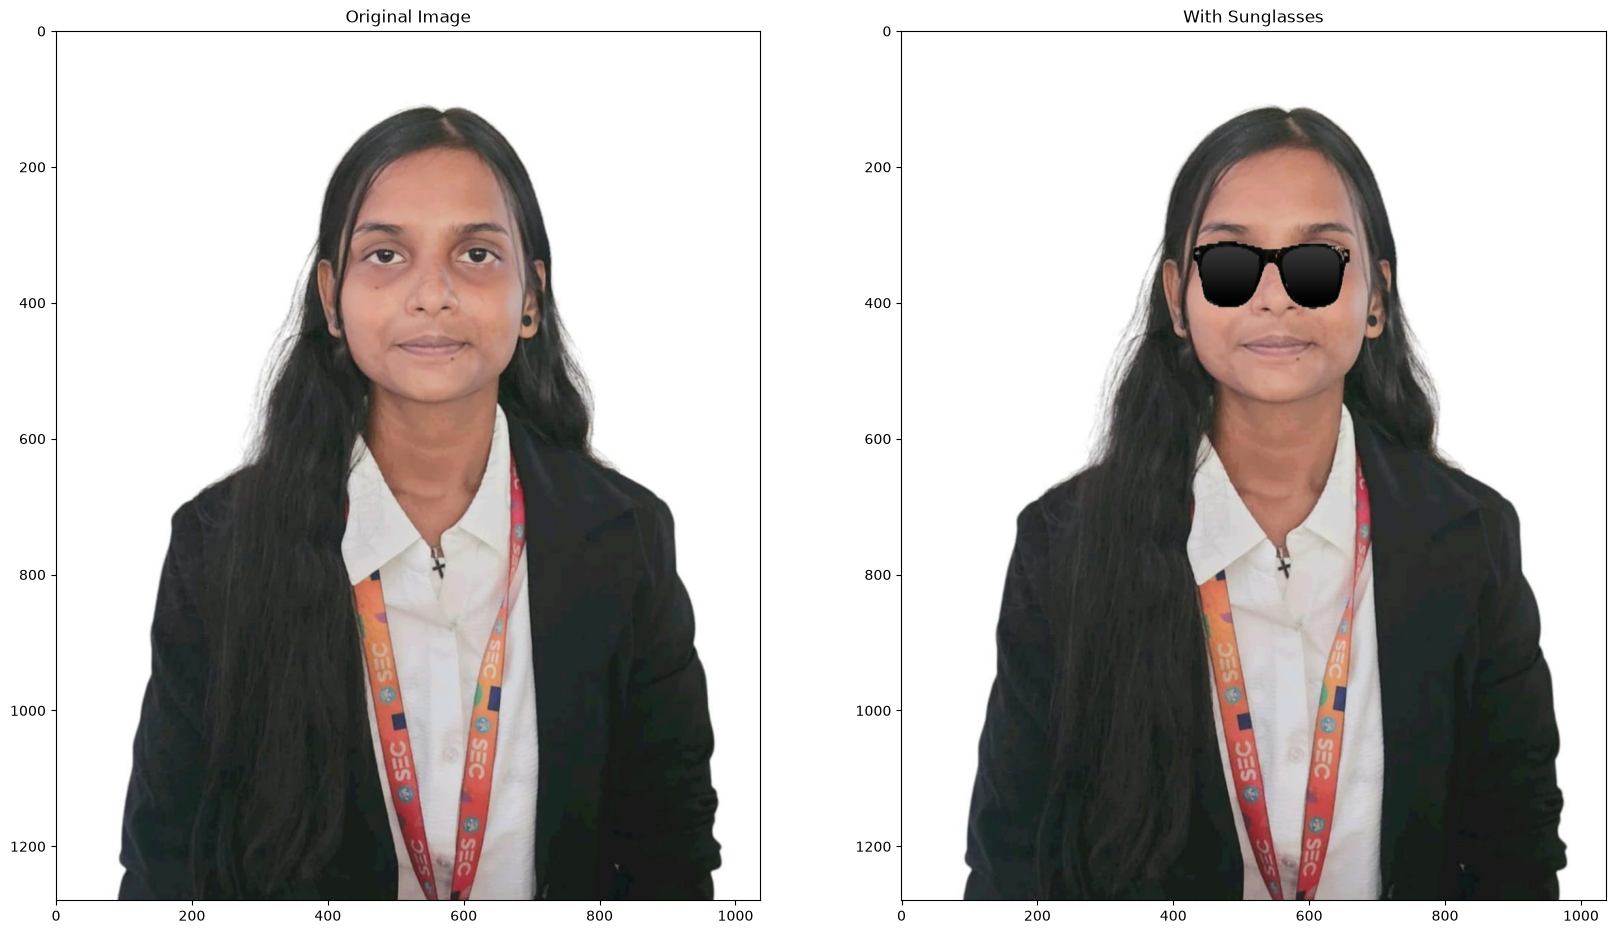

In [29]:
# Create a fresh copy of the original face image
faceWithGlassesArithmetic = faceImage.copy()

# Select the eye region
eyeROI = faceWithGlassesArithmetic[310:410, 430:660]
# Resize sunglasses and mask to match the eye region
glassBGR = cv2.resize(glassBGR, (230, 100))
glassMask1 = cv2.resize(glassMask1, (230, 100))

# Normalize the mask
glassMask = glassMask1.astype(np.float32) / 255.0

# Convert mask into 3 channels
glassMask = cv2.cvtColor(glassMask, cv2.COLOR_GRAY2BGR)

# Apply mask to the face
maskedEye = cv2.multiply(eyeROI.astype(np.float32), 1 - glassMask)

# Apply mask to sunglasses
maskedGlass = cv2.multiply(glassBGR.astype(np.float32), glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass).astype(np.uint8)

# Place sunglasses on the face
faceWithGlassesArithmetic[310:410, 430:660] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:,:,::-1])
plt.title("With Sunglasses")

plt.show()